## Introduction
Watch-It is a subscription-based media streaming
company that provides access to movies and
television programs.
The company wants to identify movies that are
likely to generate high revenue before licensing
them.
This project uses data analysis and machine
learning techniques to predict whether a movie
belongs to the High or Low revenue category.

## Project Objectives
To develop a machine learning model that predicts whether a movie belongs to the high Revenue category base on its available characteristics.

## Problem Type
This is a supervised binary classification
problem.
The target variable is revenue_category,
which contains two classes: High and Low.

Step 1: Importing the required Python libraries and loading the training dataset, testing dataset and sample submission file into the notebook.

In [132]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
sample_submission = pd.read_csv("sample_submission.csv")

Checking the shape of each dataset to determine the number of rows and columns available. This helps understand the size of the datasets before proceeding with data exploration and preparation.

In [133]:
print("Training dataset:", train.shape)
print("Testing dataset:", test.shape)
print("Testing dataset:", sample_submission.shape)

Training dataset: (2400, 22)
Testing dataset: (600, 21)
Testing dataset: (1, 2)


Displaying the column names of both the training and testing datasets to identify the available variables and understand the structure of the data.

In [134]:
print("Training columns:")
print(train.columns.tolist())

print("\nTesting columns:")
print(test.columns.tolist())

Training columns:
['title', 'country', 'genres', 'language', 'writer_count', 'title_adaption', 'censor_rating', 'release_date', 'runtime', 'dvd_release_date', 'users_votes', 'comments', 'likes', 'overall_views', 'dislikes', 'ratings_imdb', 'ratings_tomatoes', 'ratings_metacritic', 'special_award', 'awards_win', 'awards_nomination', 'revenue_category']

Testing columns:
['title', 'country', 'genres', 'language', 'writer_count', 'title_adaption', 'censor_rating', 'release_date', 'runtime', 'dvd_release_date', 'users_votes', 'comments', 'likes', 'overall_views', 'dislikes', 'ratings_imdb', 'ratings_tomatoes', 'ratings_metacritic', 'special_award', 'awards_win', 'awards_nomination']



Using head() function to display the first five rows of the training dataset, testing dataset and sample submission file. This is done to obtain an initial overview of the records, understand how the data is presented and familiarise with the variables in each dataset.

In [135]:
train.head()

,title,country,genres,language,writer_count,title_adaption,censor_rating,release_date,runtime,dvd_release_date,...,likes,overall_views,dislikes,ratings_imdb,ratings_tomatoes,ratings_metacritic,special_award,awards_win,awards_nomination,revenue_category
0,Pooh's Heffalump Movie,USA,"Animation, Comedy, Family, Fantasy, Musical, M...",English,3.0,True,G,11-Feb-05,68 min,24-May-05,...,NaN,NaN,NaN,6.4/10,80%,64/100,0,0,1,High
1,Yeh Jawaani Hai Deewani,India,"Comedy, Drama, Musical, Romance","Hindi, English, French",2.0,True,Not Rated,31-May-13,160 min,15-Jul-13,...,124.0,127528.0,12.0,7.1/10,67%,0,0,22,92,Low
2,Tae Guk Gi: The Brotherhood of War,South Korea,"Action, Drama, War",Korean,4.0,False,R,24-Sep-04,140 min,15-Feb-05,...,614.0,351123.0,18.0,8.1/10,80%,64/100,0,12,7,Low
3,"Book of Eli, The",USA,"Action, Adventure, Drama, Thriller",English,1.0,False,R,15-Jan-10,118 min,15-Jun-10,...,NaN,NaN,NaN,6.9/10,47%,53/100,0,3,16,High
4,Blind Dating,USA,"Comedy, Romance",English,1.0,False,PG-13,26-Apr-07,95 min,05-Feb-08,...,693.0,970306.0,36.0,6.1/10,25%,0,0,0,0,Low


In [136]:
test.head()

,title,country,genres,language,writer_count,title_adaption,censor_rating,release_date,runtime,dvd_release_date,...,comments,likes,overall_views,dislikes,ratings_imdb,ratings_tomatoes,ratings_metacritic,special_award,awards_win,awards_nomination
0,Delhi-6,India,"Comedy, Drama","Hindi, English",3.0,True,Not Rated,20-Feb-09,141 min,16-Jun-09,...,7.0,43.0,165008.0,13.0,6.0/10,40%,45/100,0,2,7
1,Before I Disappear,"USA, UK",Drama,English,1.0,False,Unrated,28-Nov-14,93 min,19-May-15,...,NaN,NaN,NaN,NaN,7.2/10,38%,47/100,0,16,8
2,"Good Year, A","USA, UK","Comedy, Drama, Romance","English, French, Russian",2.0,True,PG-13,10-Nov-06,117 min,27-Feb-07,...,14.0,276.0,187788.0,17.0,7.0/10,25%,47/100,0,1,2
3,Brüno,"USA, UK",Comedy,"English, German",9.0,True,R,10-Jul-09,81 min,17-Nov-09,...,81.0,301.0,200324.0,43.0,5.8/10,67%,54/100,0,2,5
4,How to Lose a Guy in 10 Days,"USA, Germany","Comedy, Romance",English,5.0,True,PG-13,07-Feb-03,116 min,01-Jul-03,...,74.0,480.0,740345.0,23.0,6.4/10,42%,45/100,0,1,8


In [137]:
sample_submission.head()

,title,revenue_category
0,Delhi-6,Low


Using info() function to examine the general information of both the training and testing datasets. This helpe understand the data types, number of entries, column names and non-null values in each dataset.

In [138]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2400 entries, 0 to 2399
Data columns (total 22 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   title               2398 non-null   object 
 1   country             2400 non-null   object 
 2   genres              2400 non-null   object 
 3   language            2395 non-null   object 
 4   writer_count        2306 non-null   float64
 5   title_adaption      2400 non-null   bool   
 6   censor_rating       2362 non-null   object 
 7   release_date        2396 non-null   object 
 8   runtime             2400 non-null   object 
 9   dvd_release_date    2331 non-null   object 
 10  users_votes         2400 non-null   object 
 11  comments            1974 non-null   float64
 12  likes               1956 non-null   float64
 13  overall_views       2083 non-null   float64
 14  dislikes            1956 non-null   float64
 15  ratings_imdb        2400 non-null   object 
 16  rating

In [139]:
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 21 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   title               600 non-null    object 
 1   country             600 non-null    object 
 2   genres              600 non-null    object 
 3   language            600 non-null    object 
 4   writer_count        571 non-null    float64
 5   title_adaption      600 non-null    bool   
 6   censor_rating       584 non-null    object 
 7   release_date        598 non-null    object 
 8   runtime             600 non-null    object 
 9   dvd_release_date    582 non-null    object 
 10  users_votes         600 non-null    object 
 11  comments            476 non-null    float64
 12  likes               477 non-null    float64
 13  overall_views       507 non-null    float64
 14  dislikes            477 non-null    float64
 15  ratings_imdb        600 non-null    object 
 16  ratings_

Checking both the training and testing datasets for duplicate records using the duplicated().sum() function. This is done to identify repeated rows that could affect the accuracy and reliability of the analysis. The results showed that there were no duplicate records in either dataset.

In [140]:
train.duplicated().sum()

np.int64(0)

In [141]:
test.duplicated().sum()

np.int64(0)

examining the training and testing datasets for missing values using the isnull().sum() function. This help identify columns containing incomplete records so that appropriate data-cleaning techniques could be applied.

In [142]:
train.isnull().sum()

title                   2
country                 0
genres                  0
language                5
writer_count           94
title_adaption          0
censor_rating          38
release_date            4
runtime                 0
dvd_release_date       69
users_votes             0
comments              426
likes                 444
overall_views         317
dislikes              444
ratings_imdb            0
ratings_tomatoes        0
ratings_metacritic      0
special_award           0
awards_win              0
awards_nomination       0
revenue_category        0
dtype: int64

In [143]:
test.isnull().sum()

title                   0
country                 0
genres                  0
language                0
writer_count           29
title_adaption          0
censor_rating          16
release_date            2
runtime                 0
dvd_release_date       18
users_votes             0
comments              124
likes                 123
overall_views          93
dislikes              123
ratings_imdb            0
ratings_tomatoes        0
ratings_metacritic      0
special_award           0
awards_win              0
awards_nomination       0
dtype: int64

Using describe() function to generate descriptive statistics for the numerical variables in the training dataset. This provide an overview of the data distribution, including the count, mean, standard deviation, minimum, maximum and quartile values.

In [144]:
train.describe()

,writer_count,comments,likes,overall_views,dislikes,special_award,awards_win,awards_nomination
count,2306.000000,1974.000000,1956.000000,2.083000e+03,1956.000000,2400.000000,2400.000000,2400.000000
mean,2.596271,546.438197,3113.894172,1.345472e+06,232.665644,0.185417,6.582917,12.698333
std,2.011586,2103.833164,10213.600411,4.030918e+06,946.288417,0.388716,16.089857,24.925965
min,1.000000,0.000000,0.000000,2.100000e+01,0.000000,0.000000,0.000000,0.000000
25%,1.000000,10.000000,99.000000,6.752950e+04,7.000000,0.000000,0.000000,1.000000
50%,2.000000,57.000000,425.000000,2.816520e+05,30.000000,0.000000,2.000000,5.000000
75%,3.000000,289.000000,1819.000000,9.855095e+05,121.250000,0.000000,6.000000,12.000000
max,28.000000,44644.000000,188526.000000,1.071502e+08,29267.000000,1.000000,235.000000,326.000000


## Handling missing values

Identifing the missing values in the training dataset and calculating their percentages to determine which columns require data cleaning.

In [145]:
missing_train = pd.DataFrame({'Missing Values': train.isnull().sum(), 'Percentage':(train.isnull().sum()/len(train))*100})
missing_train[missing_train['Missing Values'] > 0].sort_values(by='Percentage', ascending=False).round(1)

,Missing Values,Percentage
likes,444,18.5
dislikes,444,18.5
comments,426,17.8
overall_views,317,13.2
writer_count,94,3.9
dvd_release_date,69,2.9
censor_rating,38,1.6
language,5,0.2
release_date,4,0.2
title,2,0.1


Handling missing values in categorical columns by replacing them with the most frequently occurring value (mode) from the training dataset and using the same values to fill missing entries in both the training and testing datasets.

In [146]:
categorical_cols = ['language', 'release_date', 'dvd_release_date', 'censor_rating']

for col in categorical_cols: 
    mode_value = train[col].mode()[0]
    
    train[col] = train[col].fillna(mode_value)
    test[col] = test[col].fillna(mode_value)

Handling missing values in numerical columns by replacing them with the median value calculated from the training dataset. This helps retain the numerical data while reducing the influence of extreme values.

In [147]:
numerical_cols = ['comments', 'likes', 'overall_views', 'dislikes', 'writer_count']

for col in numerical_cols: 
    median_value = train[col].median()
    
    train[col] = train[col].fillna(median_value)
    test[col] = test[col].fillna(median_value)

Replacing missing movie titles in both the training and testing datasets with the word "Unknown" to ensure that the title columns do not contain missing entries.

In [148]:
train['title'] = train['title'].fillna('Unknown')
test['title'] = test['title'].fillna('Unknown')

Verifing whether the missing values have been successfully handled in both the training and testing datasets. The check confirms that the title column has zero missing values in both datasets, indicating that the missing-value treatment was successful.

In [149]:
train.isnull().sum()

title                 0
country               0
genres                0
language              0
writer_count          0
title_adaption        0
censor_rating         0
release_date          0
runtime               0
dvd_release_date      0
users_votes           0
comments              0
likes                 0
overall_views         0
dislikes              0
ratings_imdb          0
ratings_tomatoes      0
ratings_metacritic    0
special_award         0
awards_win            0
awards_nomination     0
revenue_category      0
dtype: int64

In [150]:
test.isnull().sum()

title                 0
country               0
genres                0
language              0
writer_count          0
title_adaption        0
censor_rating         0
release_date          0
runtime               0
dvd_release_date      0
users_votes           0
comments              0
likes                 0
overall_views         0
dislikes              0
ratings_imdb          0
ratings_tomatoes      0
ratings_metacritic    0
special_award         0
awards_win            0
awards_nomination     0
dtype: int64

Examining the data types of the columns in both the training and testing datasets to identify numerical and categorical variables and determine whether any further data type conversions are required during data preparation.

In [151]:
train.dtypes

title                  object
country                object
genres                 object
language               object
writer_count          float64
title_adaption           bool
censor_rating          object
release_date           object
runtime                object
dvd_release_date       object
users_votes            object
comments              float64
likes                 float64
overall_views         float64
dislikes              float64
ratings_imdb           object
ratings_tomatoes       object
ratings_metacritic     object
special_award           int64
awards_win              int64
awards_nomination       int64
revenue_category       object
dtype: object

In [152]:

test.dtypes

title                  object
country                object
genres                 object
language               object
writer_count          float64
title_adaption           bool
censor_rating          object
release_date           object
runtime                object
dvd_release_date       object
users_votes            object
comments              float64
likes                 float64
overall_views         float64
dislikes              float64
ratings_imdb           object
ratings_tomatoes       object
ratings_metacritic     object
special_award           int64
awards_win              int64
awards_nomination       int64
dtype: object

Displaying the first ten records of selected numerical columns, including runtime, users' votes, movie ratings and release dates. The purpose is to examine how the values are currently recorded and identifing columns that may require data type conversion or cleaning.

In [153]:
train[['runtime', 'users_votes', 'ratings_imdb', 'ratings_tomatoes', 
       'ratings_metacritic', 'release_date', 'dvd_release_date']].head(10)

,runtime,users_votes,ratings_imdb,ratings_tomatoes,ratings_metacritic,release_date,dvd_release_date
0,68 min,"5,654",6.4/10,80%,64/100,11-Feb-05,24-May-05
1,160 min,"33,860",7.1/10,67%,0,31-May-13,15-Jul-13
2,140 min,"35,697",8.1/10,80%,64/100,24-Sep-04,15-Feb-05
3,118 min,"2,71,524",6.9/10,47%,53/100,15-Jan-10,15-Jun-10
4,95 min,"11,251",6.1/10,25%,0,26-Apr-07,05-Feb-08
5,88 min,"52,005",5.1/10,26%,32/100,12-Apr-02,20-Aug-02
6,91 min,"5,498",6.2/10,57%,53/100,30-Oct-02,20-Jan-04
7,93 min,"1,04,379",5.8/10,61%,57/100,11-Jul-08,28-Oct-08
8,109 min,"35,956",6.9/10,36%,38/100,24-Oct-03,27-Jan-04
9,95 min,"4,39,998",7.7/10,85%,76/100,07-Aug-09,22-Dec-09


Checking the existing data types of the selected columns to determine whether numerical values and dates are correctly recognised by Python. This helps identify columns stored as text that need to be converted into appropriate data types before analysis.

In [154]:
train[['runtime', 'users_votes', 'ratings_imdb', 'ratings_tomatoes', 
       'ratings_metacritic', 'release_date', 'dvd_release_date']].dtypes

runtime               object
users_votes           object
ratings_imdb          object
ratings_tomatoes      object
ratings_metacritic    object
release_date          object
dvd_release_date      object
dtype: object

Removing the text abbreviation "min" from the runtime column and converting the remaining values into numerical format. This makes runtime suitable for mathematical operations, statistical analysis and machine learning modelling.

In [155]:
train['runtime'] = pd.to_numeric(train['runtime'].map(lambda x: str(x).replace('min', ' ').strip() if pd.notna(x) else x ), errors='coerce')
test['runtime'] = pd.to_numeric(test['runtime'].map(lambda x: str(x).replace('min', ' ').strip() if pd.notna(x) else x ), errors='coerce')

Converting the users_votes and movie rating columns into appropriate numerical formats in both the training and testing datasets. Commas are remove from users_votes, while unnecessary symbols such as /10 and % are remove from the IMDb and Tomatoes ratings. The conversion enables these variables to be use effectively in statistical analysis and machine learning modelling.

In [156]:
train['users_votes'] = pd.to_numeric(
    train['users_votes'].astype(str).str.replace(',', '', regex=False),
    errors='coerce'
)

test['users_votes'] = pd.to_numeric(
    test['users_votes'].astype(str).str.replace(',', '', regex=False),
    errors='coerce'
)

In [157]:
train['ratings_imdb'] = pd.to_numeric(
    train['ratings_imdb'].astype(str).str.replace('/10', '', regex=False),
    errors='coerce'
)

test['ratings_imdb'] = pd.to_numeric(
    test['ratings_imdb'].astype(str).str.replace('/10', '', regex=False),
    errors='coerce'
)

In [158]:
train['ratings_tomatoes'] = pd.to_numeric(
    train['ratings_tomatoes'].astype(str).str.replace('%', '', regex=False),
    errors='coerce'
)

test['ratings_tomatoes'] = pd.to_numeric(
    test['ratings_tomatoes'].astype(str).str.replace('%', '', regex=False),
    errors='coerce'
)

In [159]:
train['ratings_metacritic'] = pd.to_numeric(
    train['ratings_metacritic'].astype(str).str.replace('/100', '', regex=False),
    errors='coerce'
)

test['ratings_metacritic'] = pd.to_numeric(
    test['ratings_metacritic'].astype(str).str.replace('/100', '', regex=False),
    errors='coerce'
)

Convertig the release_date and dvd_release_date columns into datetime format in both the training and testing datasets. The conversion ensures that the dates are recognized as proper date values rather than ordinary text. This makes it easier to extract useful date information, such as release years, for further analysis and feature engineering.

In [160]:
train['release_date'] = pd.to_datetime(
    train['release_date'],
    format='%d-%b-%y',
    errors='coerce'
)

test['release_date'] = pd.to_datetime(
    test['release_date'],
    format='%d-%b-%y',
    errors='coerce'
)

train['dvd_release_date'] = pd.to_datetime(
    train['dvd_release_date'],
    format='%d-%b-%y',
    errors='coerce'
)

test['dvd_release_date'] = pd.to_datetime(
    test['dvd_release_date'],
    format='%d-%b-%y',
    errors='coerce'
)

Checking the data types of the columns in both the training and testing datasets after the conversions performed in the previous steps. It helps confirm that numerical variables, movie_ratings, runtime, users_votes and release dates have been converted into their appropriate data types.

In [161]:
train[['runtime', 'users_votes', 'ratings_imdb', 'ratings_tomatoes', 
       'ratings_metacritic', 'release_date', 'dvd_release_date']].dtypes

runtime                        int64
users_votes                    int64
ratings_imdb                 float64
ratings_tomatoes               int64
ratings_metacritic             int64
release_date          datetime64[ns]
dvd_release_date      datetime64[ns]
dtype: object

Saving the cleaned training and testing datasets into separate CSV files named clean_train.csv and clean_test.csv. The index=False argument prevents pandas from adding unnecessary index numbers to the saved files. This preserves the cleaned datasets for future use without having to repeat the earlier data-cleaning 

In [162]:
train.to_csv('clean_train.csv', index=False)
test.to_csv('clean_test.csv', index=False)

## Exploratory Data Analysis (EDA)
Exploratory Data Analysis involves examining and understanding the cleaned dataset using statistical summaries and visualizations. This step uses histograms, box plots, heat maps and comparative analysis to explore the distribution of numerical variables, identify possible outliers, examine relationships between variables and compare measures such as average movie likes and overall views. The analysis helps reveal important patterns and relationships within the dataset before proceeding to feature engineering and machine learning modelling.


In [163]:
train["revenue_category"].value_counts()

revenue_category
High    1221
Low     1179
Name: count, dtype: int64

In [164]:
(train["revenue_category"].value_counts(normalize=True) * 100).round(1)

revenue_category
High    50.9
Low     49.1
Name: proportion, dtype: float64

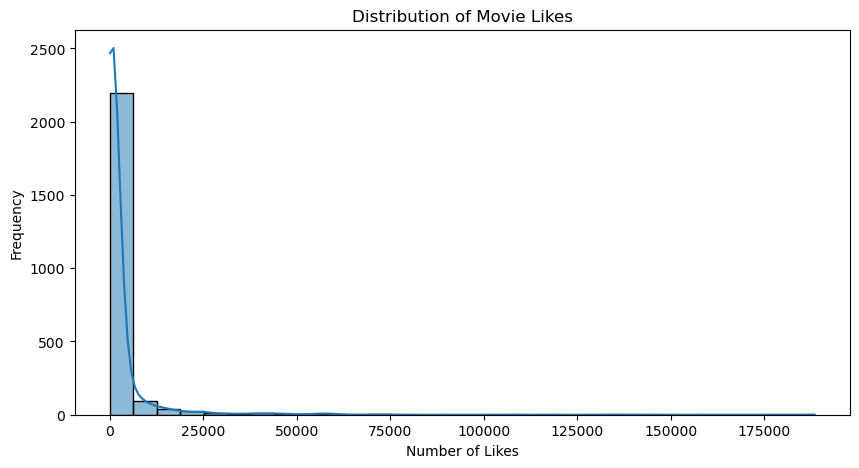

In [165]:
plt.figure(figsize=(10, 5))
sns.histplot(data=train, x= 'likes', bins=30, kde=True)
plt.title('Distribution of Movie Likes')
plt.xlabel('Number of Likes')
plt.ylabel('Frequency')
plt.show()


The histogram illustartes that the distribution of movie likes is positively skewed, with most observbation concentarted towaords the lower end and a long tail extending towards higher values. This indicates that most movies receive relatively few likes, while a small number attract exceptionally high audience engagement. The distribution is not symmetrical.

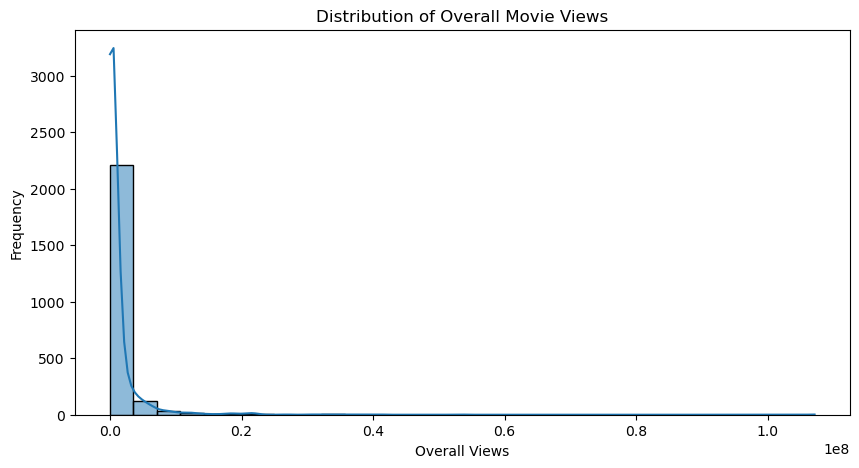

In [166]:
plt.figure(figsize=(10, 5))
sns.histplot(data=train, x='overall_views', bins=30, kde=True)
plt.title('Distribution of Overall Movie Views')
plt.xlabel('Overall Views')
plt.ylabel('Frequency')
plt.show()

The histogram shows that overall movie views are positively skewed, with most observation concentrated at the most lower end of the distribution and a long tail extending towords higher values. This indicates that a small number of movies attract exceptionally high trailer views compared with the majority.

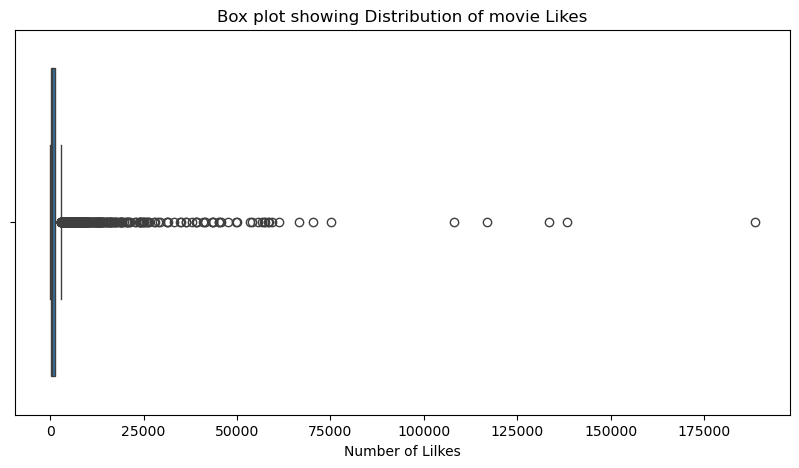

In [167]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=train['likes'])
plt.title('Box plot showing Distribution of movie Likes')
plt.xlabel('Number of Lilkes')
plt.show()

The box plot indicates that the distribution of movie likes contains numerous potential outliers, with most observations concentrated at relatively low values. The presence of extreme values suggests a positively skewed distribution, where a small number of movies receive exceptionally high audience engagement.

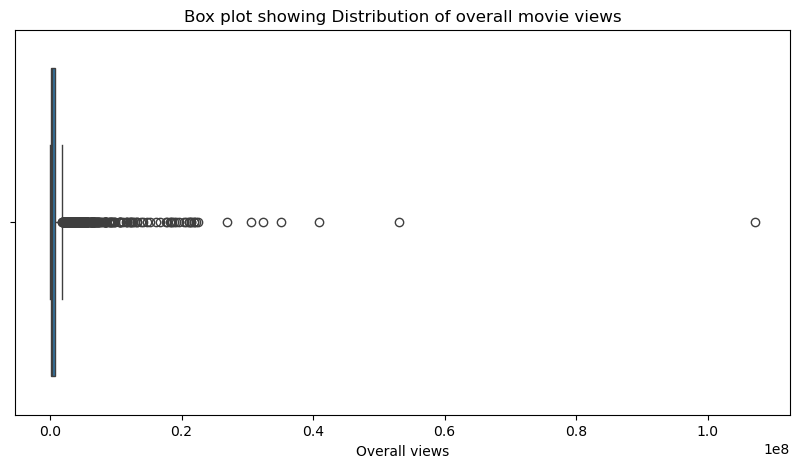

In [168]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=train['overall_views'])
plt.title('Box plot showing Distribution of overall movie views')
plt.xlabel('Overall views')
plt.show()

The box plot reveals numerous potential outliers in the overall views variable. Most observations are concentrated at relatively low views, while a small number of movies have exceptionally high views. This confirms the positively skewed distribution of observed in the histogram.

## Likes against Revenue Category

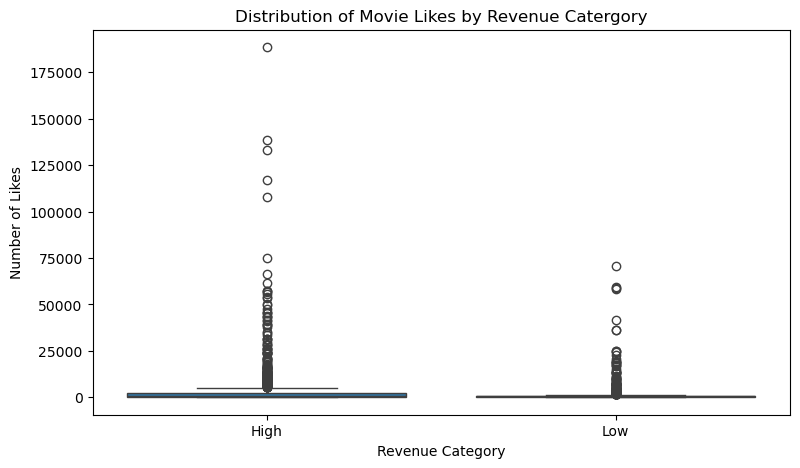

In [169]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=train, x='revenue_category', y='likes')
plt.title('Distribution of Movie Likes by Revenue Catergory')
plt.xlabel('Revenue Category')
plt.ylabel('Number of Likes')
plt.show()
    

The box plot illustrates differences in the distribution of movies likes between High and Low revenue movies appear to have higher revenue extreme values and a wider distribution of likes compared with Low revenue movies. Both categories contain numerous potential outliers, indicating considerable variation in audirence engagement. 

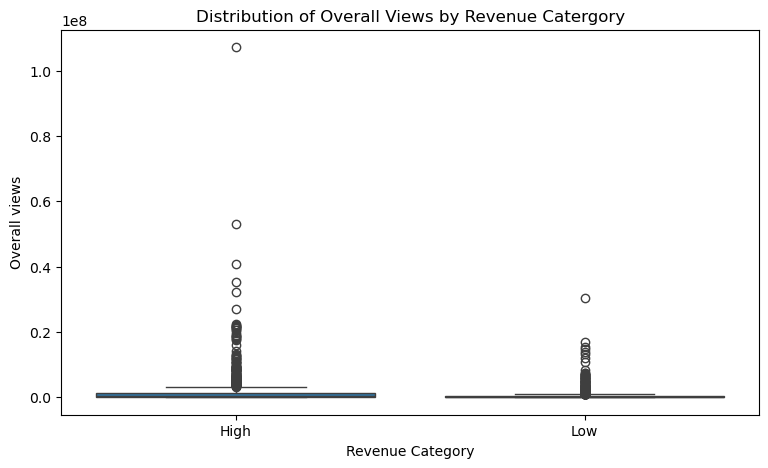

In [170]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=train, x='revenue_category', y='overall_views')
plt.title('Distribution of Overall Views by Revenue Catergory')
plt.xlabel('Revenue Category')
plt.ylabel('Overall views')
plt.show()
    

The box plot illustrates differences in overall movie views between high and low revenue categories. High revenue movies exhibit considerably higher extreme values, with some observations attracting exceptionally large numbers of views. Both categories contain potential outliers indicating substantial variations in movie popularity. The finding suggests that overall views may be an important predictor of revenue category.

## Compering average likes and views

In [171]:
train.groupby('revenue_category')[['likes', 'overall_views']].mean()

,likes,overall_views
revenue_category,,
High,3836.238329,1.777909e+06
Low,1353.206107,6.115982e+05


In [172]:
numerical_data = train.select_dtypes(include=np.number)
numerical_data.columns

Index(['writer_count', 'runtime', 'users_votes', 'comments', 'likes',
       'overall_views', 'dislikes', 'ratings_imdb', 'ratings_tomatoes',
       'ratings_metacritic', 'special_award', 'awards_win',
       'awards_nomination'],
      dtype='object')

## How numerical values relate to on another

In [173]:
correlation_matrix = numerical_data.corr()
correlation_matrix

,writer_count,runtime,users_votes,comments,likes,overall_views,dislikes,ratings_imdb,ratings_tomatoes,ratings_metacritic,special_award,awards_win,awards_nomination
writer_count,1.000000,0.015406,0.133986,0.063642,0.063345,0.057181,0.051842,-0.057582,-0.069344,-0.048987,0.061378,0.006853,0.037988
runtime,0.015406,1.000000,0.279471,0.087960,0.103439,0.083268,0.059665,0.258295,0.121812,0.109209,0.219276,0.253244,0.292029
users_votes,0.133986,0.279471,1.000000,0.226760,0.240216,0.211563,0.110923,0.314566,0.172423,0.212970,0.394390,0.504538,0.579288
comments,0.063642,0.087960,0.226760,1.000000,0.846333,0.665799,0.501081,0.018931,-0.005595,-0.000750,0.102118,0.059783,0.126180
likes,0.063345,0.103439,0.240216,0.846333,1.000000,0.763794,0.585125,0.039876,0.010912,0.002671,0.129545,0.075697,0.146463
overall_views,0.057181,0.083268,0.211563,0.665799,0.763794,1.000000,0.880621,0.012077,-0.017190,-0.005950,0.128763,0.065418,0.123573
dislikes,0.051842,0.059665,0.110923,0.501081,0.585125,0.880621,1.000000,-0.058005,-0.038712,-0.046890,0.087176,0.043300,0.067134
ratings_imdb,-0.057582,0.258295,0.314566,0.018931,0.039876,0.012077,-0.058005,1.000000,0.726755,0.605836,0.376665,0.367054,0.364848
ratings_tomatoes,-0.069344,0.121812,0.172423,-0.005595,0.010912,-0.017190,-0.038712,0.726755,1.000000,0.782389,0.363619,0.347730,0.358705
ratings_metacritic,-0.048987,0.109209,0.212970,-0.000750,0.002671,-0.005950,-0.046890,0.605836,0.782389,1.000000,0.369709,0.368653,0.385793


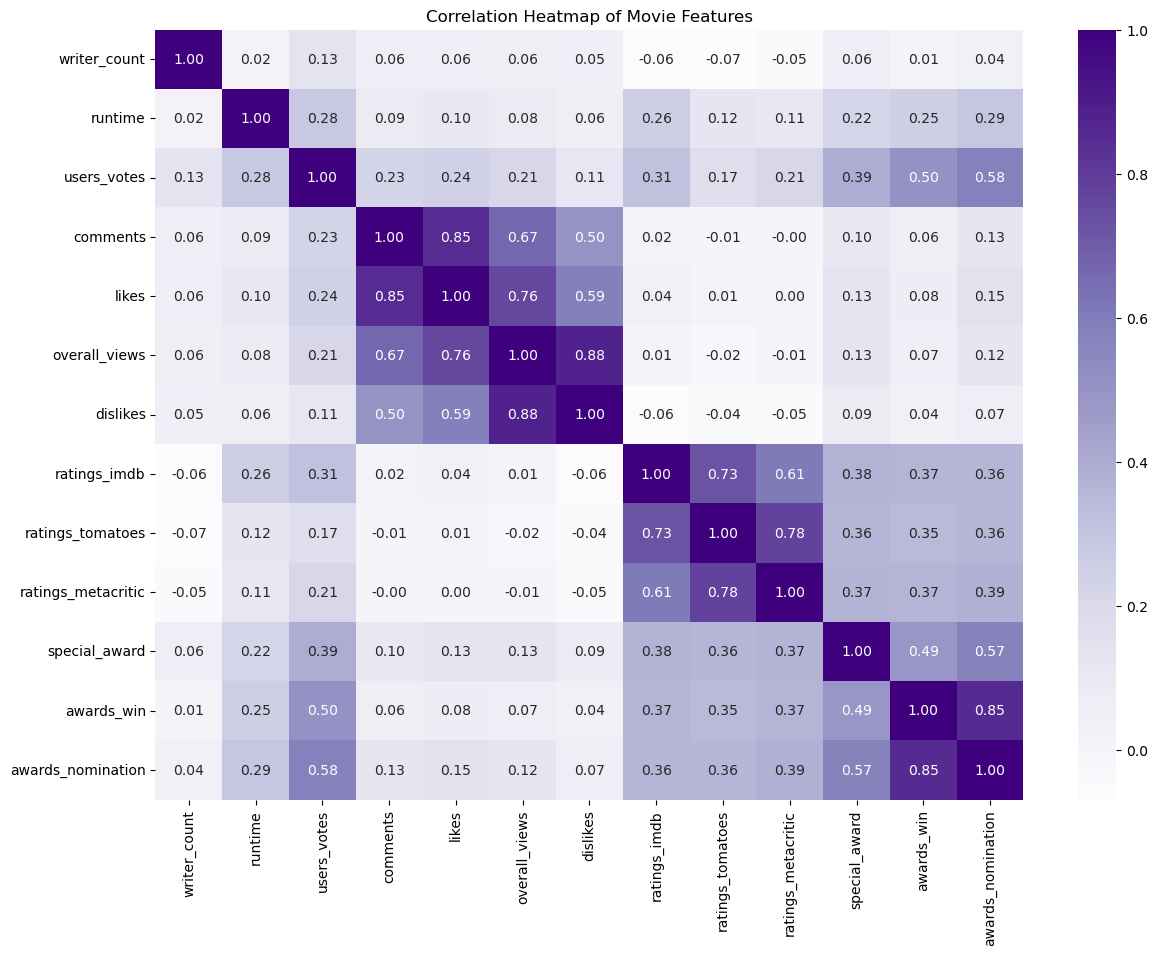

In [174]:
plt.figure(figsize=(14, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='Purples', fmt='.2f')
plt.title('Correlation Heatmap of Movie Features')
plt.show()

The correlation heatmap reveals several strong positive relationships among the variables. Likes and comments have a strong correlation of 0.85, while awards won and nominations also correlate at 0.85. Overall views are positively correlated with likes (0.76) and dislikes (0.59), suggesting that movies with more views attract more audience reactions.

Similarly, IMDb and Metacritic ratings (0.73), and Rotten Tomatoes and Metacritic ratings (0.78), show strong positive relationships, indicating similarities in movie evaluations. However, variables such as writer count and runtime show relatively weak relationships with other numerical variables.

Overall, audience engagement variables and movie ratings are closely related, while some other variables have weaker linear associations.

This step selects all columns with an object data type from the training dataset using the select_dtypes() function. It identifies categorical variables such as title, country, genres, language, censor rating and revenue category. These variables contain text-based information that may require further processing before machine learning modelling.

In [175]:
categorical_data = train.select_dtypes(include='object')
categorical_data.columns

Index(['title', 'country', 'genres', 'language', 'censor_rating',
       'revenue_category'],
      dtype='object')

Using the nunique() function to determine the number of distinct values in each categorical column of the training dataset. It helps reveal how many different categories or unique entries exist within variables such as country, genres, language and censor rating.

In [176]:
categorical_data.nunique()

title               2388
country              485
genres               586
language             474
censor_rating          8
revenue_category       2
dtype: int64

Converting the revenue_category variable from text labels into numerical values using the map() function. The High Revenue category is assigned the value 0, while the Low Revenue category is assigned the value 1. This transformation changes the target variable into a numerical format that can be understood by machine learning algorithms.

In [177]:
train['revenue_category'] = train['revenue_category'].map({
    'High': 0,'Low': 1})

Using the value_counts() function to count the observations in each category after encoding the revenue_category variable. It checks whether the High Revenue and Low Revenue categories have been successfully converted into their assigned numerical values.

In [178]:
train['revenue_category'].value_counts()

revenue_category
0    1221
1    1179
Name: count, dtype: int64

This step separates the training dataset into two components: the independent variables (x) and the dependent variable (y). The drop() function removes the revenue_category column from the training dataset to create x, while the revenue category column is assigned to y. This ensures that the model uses the available movie features to predict the revenue category.

In [179]:
x = train.drop('revenue_category', axis=1)
y = train['revenue_category']

This step checks the columns in the feature dataset x that still have an object data type. It identifies categorical variables such as title, country, genres, language and censor rating that have not yet been converted into numerical representations.

In [180]:
x.select_dtypes(include='object').columns

Index(['title', 'country', 'genres', 'language', 'censor_rating'], dtype='object')

Examining the most common genres, country, lanugauge and censor_rating using value_counts() and head() to display the top common one.

In [181]:
train['genres'].value_counts().head(10)

genres
Drama                      147
Comedy, Drama              111
Comedy, Drama, Romance     107
Comedy, Romance             88
Documentary                 86
Drama, Romance              86
Comedy                      67
Crime, Drama, Thriller      50
Action, Crime, Thriller     40
Crime, Drama                37
Name: count, dtype: int64

In [182]:
train['country'].value_counts().head(10)

country
USA             1185
France            62
UK                62
USA, Germany      54
UK, USA           52
USA, UK           51
USA, Canada       47
India             41
Germany, USA      28
Canada            21
Name: count, dtype: int64

In [183]:
train['language'].value_counts().head(10)

language
English              1318
English, Spanish      126
English, French        68
French                 39
English, Russian       27
English, Italian       25
English, German        24
English, Japanese      20
Spanish                18
French, English        17
Name: count, dtype: int64

In [184]:
train['censor_rating'].value_counts().head(10)

censor_rating
R            1009
PG-13         727
PG            276
Not Rated     262
G              53
NOT RATED      36
Unrated        26
UNRATED        11
Name: count, dtype: int64

This step uses select_dtypes() to select the remaining categorical columns in the feature dataset x and applies the nunique() function to count their distinct values. It helps identify the number of unique entries in each text-based feature before further data preparation.

In [185]:
x.select_dtypes(include='object').nunique()

title            2388
country           485
genres            586
language          474
censor_rating       8
dtype: int64

Removing the title column from both the training features (x) and testing datasets using the drop() function. Movie titles are unique text identifiers and are not directly used as predictive features in the model. Removing them helps ensure that the model learns from relevant movie characteristics rather than individual movie names.

In [186]:
x = x.drop(columns=['title'])
test = test.drop(columns=['title'])

Checking for dataset demention after removing the coulumn "title"

In [187]:
print(x.shape)
print(test.shape)

(2400, 20)
(600, 20)


This step standardizes the values in the censor_rating column in both the training and testing datasets. The str.strip() function removes unnecessary spaces, while str.upper() converts all values into uppercase letters. The replace() function also changes the category UNRATED to NOT RATED to ensure consistent naming across the datasets.

In [188]:
for df in [x, test]:
    df['censor_rating'] = df['censor_rating'].str.strip().str.upper() 
    df['censor_rating'] = df['censor_rating'].replace({'UNRATED': 'NOT RATED'
                            })

In [189]:
x['censor_rating'].value_counts()

censor_rating
R            1009
PG-13         727
NOT RATED     335
PG            276
G              53
Name: count, dtype: int64

Examining the diversity and frequency of categorical variables in the training features (X), particularly country, genres and language. The nunique() function is use to determine the number of unique entries in each variable, while value_counts().head(10) displays the ten most frequently occurring entries. The analysis identifies 485 unique country entries, 586 unique genre entries and 474 unique language entries in the dataset.

In [190]:
print('Number of unique countries:', x['country'].nunique())
print(x['country'].value_counts().head(10))     

Number of unique countries: 485
country
USA             1185
France            62
UK                62
USA, Germany      54
UK, USA           52
USA, UK           51
USA, Canada       47
India             41
Germany, USA      28
Canada            21
Name: count, dtype: int64


In [191]:
print('Number of unique genres:', x['genres'].nunique())
print(x['genres'].value_counts().head(10))     

Number of unique genres: 586
genres
Drama                      147
Comedy, Drama              111
Comedy, Drama, Romance     107
Comedy, Romance             88
Documentary                 86
Drama, Romance              86
Comedy                      67
Crime, Drama, Thriller      50
Action, Crime, Thriller     40
Crime, Drama                37
Name: count, dtype: int64


In [192]:
print('Number of unique language:', x['language'].nunique())
print(x['language'].value_counts().head(10))     

Number of unique language: 474
language
English              1318
English, Spanish      126
English, French        68
French                 39
English, Russian       27
English, Italian       25
English, German        24
English, Japanese      20
Spanish                18
French, English        17
Name: count, dtype: int64


In [193]:
x['country'].head(10)

0            USA
1          India
2    South Korea
3            USA
4            USA
5            USA
6     France, UK
7            USA
8            USA
9            USA
Name: country, dtype: object

In [194]:
test['country'].head(10)

0           India
1         USA, UK
2         USA, UK
3         USA, UK
4    USA, Germany
5             USA
6          France
7             USA
8             USA
9             USA
Name: country, dtype: object

In [195]:
x['country'].isnull().sum()

np.int64(0)

In [196]:
test['country'].isnull().sum()

np.int64(0)

This step uses a for loop to process the country column in both the training features (x) and testing datasets. The str.strip() function removes unnecessary leading and trailing spaces from country values. This ensures that country names are consistently represented across both datasets.

In [197]:
for df in [x, test]:df['country'] = df['country'].str.strip()

Combining the country columns from the training and testing datasets using pd.concat(). It then creates an empty set and uses nested for loops to split multiple country entries separated by commas into individual country names. The strip() function removes unnecessary spaces from each country name, while the add() function stores unique country names in the set. Finally, the len() function counts the total number of unique individual countries, and sorted() displays them in alphabetical order. The analysis identifies 102 unique individual countries across both datasets.

In [198]:
all_countries = pd.concat([x['country'], test['country']])

unique_countries = set()

for countries in all_countries:
    for country in countries.split(','):
        unique_countries.add(country.strip())

print("Total individual countries:", len(unique_countries))
print(sorted(unique_countries))

Total individual countries: 102
['Afghanistan', 'Albania', 'Algeria', 'Angola', 'Argentina', 'Australia', 'Austria', 'Bahamas', 'Belarus', 'Belgium', 'Bolivia', 'Bosnia and Herzegovina', 'Brazil', 'Bulgaria', 'Cambodia', 'Cameroon', 'Canada', 'Cayman Islands', 'Chad', 'Chile', 'China', 'Colombia', 'Croatia', 'Czech Republic', 'Denmark', 'Dominican Republic', 'East Germany', 'Ecuador', 'Egypt', 'Estonia', 'Ethiopia', 'Finland', 'France', 'Georgia', 'Germany', 'Ghana', 'Greece', 'Greenland', 'Hong Kong', 'Hungary', 'Iceland', 'India', 'Indonesia', 'Iran', 'Ireland', 'Isle Of Man', 'Israel', 'Italy', 'Japan', 'Jordan', 'Kenya', 'Kuwait', 'Latvia', 'Lebanon', 'Lithuania', 'Luxembourg', 'Malaysia', 'Malta', 'Mauritania', 'Mexico', 'Monaco', 'Mongolia', 'Morocco', 'Namibia', 'Netherlands', 'New Zealand', 'Nigeria', 'Norway', 'Palestine', 'Paraguay', 'Peru', 'Philippines', 'Poland', 'Portugal', 'Qatar', 'Romania', 'Russia', 'Saudi Arabia', 'Serbia', 'Singapore', 'Slovakia', 'Slovenia', 'South

This step uses MultiLabelBinarizer from Scikit-learn to convert the country information in both the training and testing datasets into numerical features. First, multiple country entries associated with each movie are separated into individual country names. The encoder is then fitted using the training data only and applied to both datasets to ensure consistent encoding. Finally, the encoded country values are converted into separate binary columns and added to the respective datasets. Each binary column represents an individual country, with values indicating whether a movie is associated with that country.

In [199]:
from sklearn.preprocessing import MultiLabelBinarizer
# Separate individual countries in each movie
train_countries = x['country'].apply(lambda value: [c.strip() for c in value.split(',')])
test_countries = test['country'].apply(lambda value: [c.strip() for c in value.split(',')])

# Fit the encoder using training data only
country_encoder = MultiLabelBinarizer()
train_encoded = country_encoder.fit_transform(train_countries)

# Apply the same encoder to test data
test_encoded = country_encoder.transform(test_countries)

# Create encoded DataFrames
train_country_df = pd.DataFrame(
    train_encoded,
    columns=['country_' + c for c in country_encoder.classes_],
    index=x.index
)

test_country_df = pd.DataFrame(
    test_encoded,
    columns=['country_' + c for c in country_encoder.classes_],
    index=test.index
)

# Add encoded features to both datasets
x = pd.concat([x.drop(columns=['country']), train_country_df], axis=1)
test = pd.concat([test.drop(columns=['country']), test_country_df], axis=1)

print("Training dataset shape:", x.shape)
print("Testing dataset shape:", test.shape)

Training dataset shape: (2400, 114)
Testing dataset shape: (600, 114)


C:\New folder\Lib\site-packages\sklearn\preprocessing\_label.py:909: UserWarning: unknown class(es) ['Angola', 'East Germany', 'Estonia', 'Kuwait', 'Palestine', 'Venezuela', 'West Germany'] will be ignored
  warnings.warn(


In [200]:
print(x['genres'].head(10))
print(test['genres'].head(10))

0    Animation, Comedy, Family, Fantasy, Musical, M...
1                      Comedy, Drama, Musical, Romance
2                                   Action, Drama, War
3                   Action, Adventure, Drama, Thriller
4                                      Comedy, Romance
5                                      Comedy, Romance
6                                      Comedy, Romance
7           Action, Adventure, Family, Fantasy, Sci-Fi
8                              Biography, Drama, Sport
9                               Comedy, Drama, Romance
Name: genres, dtype: object
0                                    Comedy, Drama
1                                            Drama
2                           Comedy, Drama, Romance
3                                           Comedy
4                                  Comedy, Romance
5                                   Drama, Romance
6                                   Drama, Romance
7                        Action, Adventure, Sci-Fi
8             

Standardizing the values in the genres column in both the training features (x) and testing datasets. The str.strip() function removes unnecessary spaces at the beginning and end of each genre entry, while str.replace() with a regular expression removes extra spaces within the genre descriptions. This ensures that genre entries are consistently formatted across both datasets.

In [201]:
for df in [x, test]:
    df['genres'] = df['genres'].str.strip()
    df['genres'] = df['genres'].str.replace(r'\s*,\s*', ', ', regex=True)

combining the genre columns from the training and testing datasets

In [202]:
all_genres = pd.concat([x['genres'], test['genres']])

unique_genres = set()

for genres in all_genres:
    for genre in genres.split(','):
        unique_genres.add(genre.strip())

print("Total individual genres:", len(unique_genres))
print(sorted(unique_genres))

Total individual genres: 24
['Action', 'Adventure', 'Animation', 'Biography', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Family', 'Fantasy', 'Film-Noir', 'History', 'Horror', 'Music', 'Musical', 'Mystery', 'News', 'Romance', 'Sci-Fi', 'Short', 'Sport', 'Thriller', 'War', 'Western']


Using MultiLabelBinarizer from Scikit-learn to convert movie genres into numerical binary features

In [203]:
mlb_genres = MultiLabelBinarizer(classes=sorted(unique_genres))

train_genres = mlb_genres.fit_transform(x['genres'].str.split(', '))
test_genres = mlb_genres.transform(test['genres'].str.split(', '))

train_genres_df = pd.DataFrame(
    train_genres,
    columns=['genre_' + g for g in mlb_genres.classes_],
    index=x.index
)

test_genres_df = pd.DataFrame(
    test_genres,
    columns=['genre_' + g for g in mlb_genres.classes_],
    index=test.index
)

Checking the Dimensions of Encoded Genre Features

In [204]:
print(train_genres_df.shape)
print(test_genres_df.shape)

(2400, 24)
(600, 24)


In [205]:
train_genres_df.head()

,genre_Action,genre_Adventure,genre_Animation,genre_Biography,genre_Comedy,genre_Crime,genre_Documentary,genre_Drama,genre_Family,genre_Fantasy,...,genre_Musical,genre_Mystery,genre_News,genre_Romance,genre_Sci-Fi,genre_Short,genre_Sport,genre_Thriller,genre_War,genre_Western
0,0,0,1,0,1,0,0,0,1,1,...,1,1,0,0,0,0,0,0,0,0
1,0,0,0,0,1,0,0,1,0,0,...,1,0,0,1,0,0,0,0,0,0
2,1,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,1,0
3,1,1,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
4,0,0,0,0,1,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0


Combining Encoded Genre Features with the Original Datasets
This step combines the newly created binary genre features with the remaining columns in the training and testing datasets

In [206]:
x = pd.concat([x.drop(columns=['genres']), train_genres_df], axis=1)

test = pd.concat([test.drop(columns=['genres']), test_genres_df], axis=1)

print("Training dataset:", x.shape)
print("Testing dataset:", test.shape)

Training dataset: (2400, 137)
Testing dataset: (600, 137)


Identifying Remaining Text-Based Columns

In [207]:
print("Training text columns:")
print(x.select_dtypes(include='object').columns.tolist())

print("\nTesting text columns:")
print(test.select_dtypes(include='object').columns.tolist())

Training text columns:
['language', 'censor_rating']

Testing text columns:
['language', 'censor_rating']


Identifying Country-Related Encoded Features
This step uses a list comprehension to identify all columns in the training dataset whose names contain the word country. It displays the country-related binary features created during the multi-label binarization process, such as country_Afghanistan, country_Albania and country_Algeria. These columns represent individual countries as separate numerical features


In [208]:
print("country-related columns:")
print([col for col in x.columns if 'country' in col.lower()]) 

country-related columns:
['country_Afghanistan', 'country_Albania', 'country_Algeria', 'country_Argentina', 'country_Australia', 'country_Austria', 'country_Bahamas', 'country_Belarus', 'country_Belgium', 'country_Bolivia', 'country_Bosnia and Herzegovina', 'country_Brazil', 'country_Bulgaria', 'country_Cambodia', 'country_Cameroon', 'country_Canada', 'country_Cayman Islands', 'country_Chad', 'country_Chile', 'country_China', 'country_Colombia', 'country_Croatia', 'country_Czech Republic', 'country_Denmark', 'country_Dominican Republic', 'country_Ecuador', 'country_Egypt', 'country_Ethiopia', 'country_Finland', 'country_France', 'country_Georgia', 'country_Germany', 'country_Ghana', 'country_Greece', 'country_Greenland', 'country_Hong Kong', 'country_Hungary', 'country_Iceland', 'country_India', 'country_Indonesia', 'country_Iran', 'country_Ireland', 'country_Isle Of Man', 'country_Israel', 'country_Italy', 'country_Japan', 'country_Jordan', 'country_Kenya', 'country_Latvia', 'country_

Examining the Distribution of Remaining Categorical Values

In [209]:
for column in ['language', 'censor_rating']:
    print(f"\n{column} unique values:")
    print(x[column].value_counts())


language unique values:
language
English                                        1318
English, Spanish                                126
English, French                                  68
French                                           39
English, Russian                                 27
                                               ... 
English, Romany, Romanian, Ukrainian              1
English, Romanian, Hebrew, Polish, Armenian       1
Hindi, English, German                            1
Hindi, Cantonese, English                         1
English, Italian, Portuguese                      1
Name: count, Length: 474, dtype: int64

censor_rating unique values:
censor_rating
R            1009
PG-13         727
NOT RATED     335
PG            276
G              53
Name: count, dtype: int64


Verifying Remaining Text-Based Columns

In [210]:
print("Training text columns:")
print(x.select_dtypes(include='object').columns.tolist())

print("\nTesting text columns:")
print(test.select_dtypes(include='object').columns.tolist())

Training text columns:
['language', 'censor_rating']

Testing text columns:
['language', 'censor_rating']


Creating Dummy Variables for Censor Ratings
This step converts the categorical censor_rating variable into numerical dummy variables using pd.get_dummies() in both the training and testing datasets. Each censor rating is represented by a separate binary column, with 1 indicating the presence of a category and 0 indicating its absence. The testing dataset is then aligned with the training dataset to ensure both have the same columns, making the data suitable for machine learning modelling.


In [211]:
train_censor_df = pd.get_dummies(
    x['censor_rating'],
    prefix='censor_rating',
    dtype=int
)

test_censor_df = pd.get_dummies(
    test['censor_rating'],
    prefix='censor_rating',
    dtype=int
)

test_censor_df = test_censor_df.reindex(
    columns=train_censor_df.columns,
    fill_value=0
)

print(train_censor_df.shape)
print(test_censor_df.shape)

(2400, 5)
(600, 5)


Combining Censor Rating Dummy Variables with the Datasets

In [212]:
x = pd.concat(
    [x.drop(columns=['censor_rating']), train_censor_df],
    axis=1
)

test = pd.concat(
    [test.drop(columns=['censor_rating']), test_censor_df],
    axis=1
)

print("Training dataset:", x.shape)
print("Testing dataset:", test.shape)

Training dataset: (2400, 141)
Testing dataset: (600, 141)


Combining Language Dummy Variables with the Datasets
This step combines the newly created language dummy variables with the original training and testing datasets

In [213]:
all_languages = pd.concat([x['language'], test['language']])

unique_languages = set()

for languages in all_languages:
    for language in languages.split(','):
        unique_languages.add(language.strip())

print("Total individual languages:", len(unique_languages))
print(sorted(unique_languages))

Total individual languages: 131
['Aboriginal', 'Acholi', 'Afrikaans', 'Albanian', 'Algonquin', 'American Sign Language', 'Amharic', 'Ancient (to 1453)', 'Apache languages', 'Arabic', 'Aramaic', 'Armenian', 'Awadhi', 'Balinese', 'Bambara', 'Bengali', 'Bhojpuri', 'Bosnian', 'Bulgarian', 'Burmese', 'Cantonese', 'Catalan', 'Chechen', 'Chinese', 'Corsican', 'Croatian', 'Czech', 'Danish', 'Dari', 'Dutch', 'English', 'Esperanto', 'Estonian', 'Filipino', 'Finnish', 'Flemish', 'French', 'Georgian', 'German', 'Greek', 'Greenlandic', 'Gujarati', 'Hakka', 'Hausa', 'Hawaiian', 'Hebrew', 'Hindi', 'Hmong', 'Hungarian', 'Ibo', 'Icelandic', 'Indonesian', 'Inuktitut', 'Irish', 'Italian', 'Japanese', 'Khmer', 'Kinyarwanda', 'Kirundi', 'Klingon', 'Korean', 'Lao', 'Latin', 'Lithuanian', 'Low German', 'Macedonian', 'Mandarin', 'Manipuri', 'Maori', 'Masai', 'Maya', 'Mende', 'Min Nan', 'Mohawk', 'Mongolian', 'Navajo', 'Neapolitan', 'None', 'Norse', 'North American Indian', 'Norwegian', 'Nyanja', 'Old', 'Old E

In [214]:
from sklearn.preprocessing import MultiLabelBinarizer

# Split languages into individual languages
train_languages = x['language'].str.split(',')
test_languages = test['language'].str.split(',')

# Remove extra spaces
train_languages = train_languages.apply(
    lambda languages: [language.strip() for language in languages]
)

test_languages = test_languages.apply(
    lambda languages: [language.strip() for language in languages]
)

# Create the encoder
mlb_languages = MultiLabelBinarizer()

# Encode training and testing languages
train_languages_df = pd.DataFrame(
    mlb_languages.fit_transform(train_languages),
    columns=['language_' + language for language in mlb_languages.classes_],
    index=x.index
)

test_languages_df = pd.DataFrame(
    mlb_languages.transform(test_languages),
    columns=train_languages_df.columns,
    index=test.index
)

# Check the results
print(train_languages_df.shape)
print(test_languages_df.shape)

(2400, 118)
(600, 118)


C:\New folder\Lib\site-packages\sklearn\preprocessing\_label.py:909: UserWarning: unknown class(es) ['Amharic', 'Ancient (to 1453)', 'Apache languages', 'Bosnian', 'Chechen', 'Hausa', 'Low German', 'Mende', 'Norse', 'Nyanja', 'Old', 'Old English', 'Quenya'] will be ignored
  warnings.warn(


Combining Language Dummy Variables with the Datasets
This step combines the newly created language dummy variables with the original training and testing datasets. The original language column is removed and replaced with numerical columns representing individual languages. This increases the number of features to 258 in both datasets and prepares the language information for machine learning modelling.


In [215]:
x = pd.concat(
    [x.drop(columns=['language']), train_languages_df],
    axis=1
)

test = pd.concat(
    [test.drop(columns=['language']), test_languages_df],
    axis=1
)

print("Training dataset:", x.shape)
print("Testing dataset:", test.shape)

Training dataset: (2400, 258)
Testing dataset: (600, 258)


Verifying the Removal of Categorical Text Columns


In [216]:
print("Training text columns:")
print(x.select_dtypes(include='object').columns.tolist())

print("\nTesting text columns:")
print(test.select_dtypes(include='object').columns.tolist())

Training text columns:
[]

Testing text columns:
[]


In [217]:
print(x.isnull().sum())
print(test.isnull().sum())

writer_count        0
title_adaption      0
release_date        0
runtime             0
dvd_release_date    0
                   ..
language_Wolof      0
language_Xhosa      0
language_Yiddish    0
language_Yoruba     0
language_Zulu       0
Length: 258, dtype: int64
writer_count        0
title_adaption      0
release_date        0
runtime             0
dvd_release_date    0
                   ..
language_Wolof      0
language_Xhosa      0
language_Yiddish    0
language_Yoruba     0
language_Zulu       0
Length: 258, dtype: int64


In [218]:
print(x.dtypes.value_counts())
print(test.dtypes.value_counts())

int64             249
float64             6
datetime64[ns]      2
bool                1
Name: count, dtype: int64
int64             249
float64             6
datetime64[ns]      2
bool                1
Name: count, dtype: int64


## Model Preparation, Training, Evaluation and Comparison
## Preparing the Features for Modelling
Before training the machine-learning models, the prepared training, validation and testing datasets were examined to ensure that they were suitable for modelling. The country-related features were identified and counted to understand how many features had been generated during feature engineering. The training, validation and testing datasets were also compared to confirm that they contained the same feature columns in the same order. This is important because machine-learning models require consistent input features when learning from training data and making predictions on new data.
The shapes of the datasets were checked to confirm the number of observations and features available for modelling. The training dataset contained 1,920 observations and 234 features. The data types were also examined to ensure that the model inputs were numerical. Descriptive statistics, including the minimum and maximum values, were reviewed to understand the distribution and ranges of the numerical features.

In [219]:
# encoder using all languages identified
mlb_languages = MultiLabelBinarizer(
    classes=sorted(unique_languages)
)

# Encode training languages
train_languages_df = pd.DataFrame(
    mlb_languages.fit_transform(train_languages),
    columns=['language_' + language for language in mlb_languages.classes_],
    index=x.index
)

# Encode testing languages
test_languages_df = pd.DataFrame(
    mlb_languages.transform(test_languages),
    columns=train_languages_df.columns,
    index=test.index
)

# Confirm the number of language features
print("Training language features:", train_languages_df.shape)
print("Testing language features:", test_languages_df.shape)

Training language features: (2400, 131)
Testing language features: (600, 131)


In [220]:
x = pd.concat(
    [x, train_languages_df],
    axis=1
)

test = pd.concat(
    [test, test_languages_df],
    axis=1
)

print("Training dataset:", x.shape)
print("Testing dataset:", test.shape)

Training dataset: (2400, 389)
Testing dataset: (600, 389)


In [221]:
print(x.duplicated().sum())
print(test.duplicated().sum())

0
0


In [222]:
print(x.columns.duplicated().sum())
print(test.columns.duplicated().sum())

118
118


In [223]:
# Removing duplicate column names, keeping the first occurrence
x = x.loc[:, ~x.columns.duplicated()]
test = test.loc[:, ~test.columns.duplicated()]

# Confirming the results
print("Training dataset:", x.shape)
print("Testing dataset:", test.shape)

print("Duplicate training columns:", x.columns.duplicated().sum())
print("Duplicate testing columns:", test.columns.duplicated().sum())

Training dataset: (2400, 271)
Testing dataset: (600, 271)
Duplicate training columns: 0
Duplicate testing columns: 0


In [224]:
x.columns.equals(test.columns)

True

In [225]:
print(x[['release_date', 'dvd_release_date']].dtypes)

release_date        datetime64[ns]
dvd_release_date    datetime64[ns]
dtype: object


In [226]:
# Extracting release year from both date columns
for df in [x, test]:
    df['release_year'] = df['release_date'].dt.year
    df['dvd_release_year'] = df['dvd_release_date'].dt.year

print(x[['release_year', 'dvd_release_year']].head())

   release_year  dvd_release_year
0          2005              2005
1          2013              2013
2          2004              2005
3          2010              2010
4          2007              2008


In [227]:
print(test.shape)
print(x.shape)

(600, 273)
(2400, 273)


In [228]:
print(x.select_dtypes(include='object').columns.tolist())
print(x.select_dtypes(include='object').columns.tolist())

[]
[]


In [229]:
print(x.isnull().sum().sum())
print(test.isnull().sum().sum())

0
0


In [230]:
print("Infinite values in training data:", np.isinf(x.select_dtypes(include=np.number)).sum().sum())
print("Infinite values in testing data:", np.isinf(test.select_dtypes(include=np.number)).sum().sum())

Infinite values in training data: 0
Infinite values in testing data: 0


In [231]:
print(x.dtypes.value_counts())
print(test.dtypes.value_counts())

int64             262
float64             6
datetime64[ns]      2
int32               2
bool                1
Name: count, dtype: int64
int64             262
float64             6
datetime64[ns]      2
int32               2
bool                1
Name: count, dtype: int64


In [232]:
print(x.select_dtypes(include='bool').columns.tolist())

['title_adaption']


In [233]:
# Removing original date columns after extracting the years
x = x.drop(columns=['release_date', 'dvd_release_date'])
test = test.drop(columns=['release_date', 'dvd_release_date'])

# Confirming the results
print("Training dataset:", x.shape)
print("Testing dataset:", test.shape)

Training dataset: (2400, 271)
Testing dataset: (600, 271)


In [234]:
print(x['title_adaption'].value_counts())
print(test['title_adaption'].value_counts())

title_adaption
False    1202
True     1198
Name: count, dtype: int64
title_adaption
True     317
False    283
Name: count, dtype: int64


In [235]:
# Converting Boolean values into numerical values
for df in [x, test]:
    df['title_adaption'] = df['title_adaption'].astype(int)

# Confirming the conversion
print(x['title_adaption'].value_counts())
print(test['title_adaption'].value_counts())

title_adaption
0    1202
1    1198
Name: count, dtype: int64
title_adaption
1    317
0    283
Name: count, dtype: int64


In [236]:
print(x.dtypes.value_counts())
print(test.dtypes.value_counts())

int64      263
float64      6
int32        2
Name: count, dtype: int64
int64      263
float64      6
int32        2
Name: count, dtype: int64


In [237]:
list(x.columns) == list(test.columns)

True

In [238]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    x, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Training target:", y_train.shape)
print("Validation target:", y_val.shape)

Training features: (1920, 271)
Validation features: (480, 271)
Training target: (1920,)
Validation target: (480,)


In [239]:
print(y_train.value_counts())
print(y_val.value_counts())

revenue_category
0    977
1    943
Name: count, dtype: int64
revenue_category
0    244
1    236
Name: count, dtype: int64


In [240]:
print(X_train.select_dtypes(include=['datetime']).columns.tolist())

[]


In [241]:
print(X_train.select_dtypes(include='object').columns.tolist())
print(X_val.select_dtypes(include='object').columns.tolist())

[]
[]


In [242]:
print(X_train.isnull().sum().sum())
print(X_val.isnull().sum().sum())

0
0


In [243]:
print("Infinite values in training data:", np.isinf(X_train.select_dtypes(include=np.number)).sum().sum())
print("Infinite values in testing data:", np.isinf(X_val.select_dtypes(include=np.number)).sum().sum())

Infinite values in training data: 0
Infinite values in testing data: 0


In [244]:
X_train.describe().T[['mean', 'std', 'min', 'max']]

,mean,std,min,max
writer_count,2.553646,1.919223,1.0,26.0
title_adaption,0.496875,0.500120,0.0,1.0
runtime,105.540625,18.288562,41.0,272.0
users_votes,82955.938021,143897.648269,55.0,2070977.0
comments,482.496354,2029.455880,0.0,44644.0
...,...,...,...,...
language_Old,0.000000,0.000000,0.0,0.0
language_Old English,0.000000,0.000000,0.0,0.0
language_Quenya,0.000000,0.000000,0.0,0.0
release_year,2008.491146,6.153154,1971.0,2067.0


In [245]:
constant_columns = X_train.columns[X_train.nunique() <= 1].tolist()

print("Number of constant features:", len(constant_columns))
print("Constant features:", constant_columns)

Number of constant features: 32
Constant features: ['country_Bahamas', 'country_Ethiopia', 'country_Ghana', 'country_Greenland', 'country_Kenya', 'country_Monaco', 'country_Morocco', 'country_Namibia', 'country_Qatar', 'genre_Film-Noir', 'language_Algonquin', 'language_Aramaic', 'language_Bhojpuri', 'language_Esperanto', 'language_Kirundi', 'language_Lithuanian', 'language_Neapolitan', 'language_Sindarin', 'language_Syriac', 'language_Amharic', 'language_Ancient (to 1453)', 'language_Apache languages', 'language_Bosnian', 'language_Chechen', 'language_Hausa', 'language_Low German', 'language_Mende', 'language_Norse', 'language_Nyanja', 'language_Old', 'language_Old English', 'language_Quenya']


In [246]:
X_train = X_train.drop(columns=constant_columns)
X_val = X_val.drop(columns=constant_columns)
test = test.drop(columns=constant_columns)

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Test features:", test.shape)

Training features: (1920, 239)
Validation features: (480, 239)
Test features: (600, 239)


In [247]:
duplicate_features = X_train.T.duplicated()
print(duplicate_features.sum())
print(X_train.columns[duplicate_features].tolist())
      

5
['country_Saudi Arabia', 'country_Uruguay', 'language_Masai', 'language_Songhay', 'language_Tamashek']


In [248]:
duplicate_columns = X_train.columns[duplicate_features].tolist()

X_train = X_train.drop(columns=duplicate_columns)
X_val = X_val.drop(columns=duplicate_columns)
test = test.drop(columns=duplicate_columns)

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Test features:", test.shape)

Training features: (1920, 234)
Validation features: (480, 234)
Test features: (600, 234)


In [249]:
country_columns = X_train.filter(like='country_').columns.tolist()

print("Number of country features:", len(country_columns))
print("Country features:")
print(country_columns)

Number of country features: 84
Country features:
['country_Afghanistan', 'country_Albania', 'country_Algeria', 'country_Argentina', 'country_Australia', 'country_Austria', 'country_Belarus', 'country_Belgium', 'country_Bolivia', 'country_Bosnia and Herzegovina', 'country_Brazil', 'country_Bulgaria', 'country_Cambodia', 'country_Cameroon', 'country_Canada', 'country_Cayman Islands', 'country_Chad', 'country_Chile', 'country_China', 'country_Colombia', 'country_Croatia', 'country_Czech Republic', 'country_Denmark', 'country_Dominican Republic', 'country_Ecuador', 'country_Egypt', 'country_Finland', 'country_France', 'country_Georgia', 'country_Germany', 'country_Greece', 'country_Hong Kong', 'country_Hungary', 'country_Iceland', 'country_India', 'country_Indonesia', 'country_Iran', 'country_Ireland', 'country_Isle Of Man', 'country_Israel', 'country_Italy', 'country_Japan', 'country_Jordan', 'country_Latvia', 'country_Lebanon', 'country_Lithuania', 'country_Luxembourg', 'country_Malaysia

In [250]:
print(list(X_train.columns) == list(X_val.columns))
print(list(X_train.columns) == list(test.columns))

True
True


In [251]:
print(X_train.shape)
print(X_val.shape)
print(test.shape)

(1920, 234)
(480, 234)
(600, 234)


In [252]:
print(X_train.dtypes.value_counts())

int64      226
float64      6
int32        2
Name: count, dtype: int64


In [253]:
X_train.describe().loc[['min','max']].T

,min,max
writer_count,1.0,26.0
title_adaption,0.0,1.0
runtime,41.0,272.0
users_votes,55.0,2070977.0
comments,0.0,44644.0
...,...,...
language_Yiddish,0.0,1.0
language_Yoruba,0.0,1.0
language_Zulu,0.0,1.0
release_year,1971.0,2067.0


In [254]:
X_train[['users_votes', 'comments', 'runtime', 'writer_count']].describe()

,users_votes,comments,runtime,writer_count
count,1.920000e+03,1920.000000,1920.000000,1920.000000
mean,8.295594e+04,482.496354,105.540625,2.553646
std,1.438976e+05,2029.455880,18.288562,1.919223
min,5.500000e+01,0.000000,41.000000,1.000000
25%,6.769750e+03,15.000000,93.000000,1.000000
50%,2.903550e+04,57.000000,102.000000,2.000000
75%,9.525925e+04,221.250000,114.000000,3.000000
max,2.070977e+06,44644.000000,272.000000,26.000000


## Feature Scaling Using StandardScaler
Feature scaling was performed using the StandardScaler method from Scikit-learn. This technique standardises numerical features by transforming them to have a mean of approximately zero and a standard deviation of approximately one. Scaling is particularly important for Logistic Regression because the model can be affected when input variables have substantially different numerical ranges.
The scaler was fitted using only the training dataset and then applied to the training, validation and testing datasets. This approach prevents information from the validation and testing datasets from influencing the scaling process. The scaled datasets were stored separately as X_train_scaled, X_val_scaled and test_scaled, while retaining the original feature names and indexes. This ensured that the data was properly prepared for model training and evaluation.

In [255]:
from sklearn.preprocessing import StandardScaler
import pandas as pd

scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_val_scaled = pd.DataFrame(
    scaler.transform(X_val),
    columns=X_val.columns,
    index=X_val.index
)

test_scaled = pd.DataFrame(
    scaler.transform(test),
    columns=test.columns,
    index=test.index
)

In [256]:
X_train_scaled.head()

,writer_count,title_adaption,runtime,users_votes,comments,likes,overall_views,dislikes,ratings_imdb,ratings_tomatoes,...,language_Urdu,language_Vietnamese,language_Welsh,language_Wolof,language_Xhosa,language_Yiddish,language_Yoruba,language_Zulu,release_year,dvd_release_year
353,-0.288549,-0.993769,0.407977,2.355225,0.504948,0.543753,0.472587,0.040264,1.211874,-0.842879,...,-0.072357,-0.051098,-0.022828,-0.022828,-0.032292,-0.045691,-0.022828,-0.032292,-0.730083,-0.419711
1135,-0.809729,-0.993769,1.939388,-0.552070,-0.237316,-0.277100,-0.314034,-0.224773,0.411290,0.828800,...,-0.072357,-0.051098,-0.022828,-0.022828,-0.032292,-0.045691,-0.022828,-0.032292,-1.055205,-1.648134
1672,0.753811,1.006270,-0.576501,-0.522326,-0.209715,-0.234729,-0.244397,-0.192187,-3.791778,-1.554232,...,-0.072357,-0.051098,-0.022828,-0.022828,-0.032292,-0.045691,-0.022828,-0.032292,-0.567523,-0.665396
1111,-0.809729,-0.993769,0.189204,0.890261,-0.209715,-0.234729,-0.244397,-0.192187,1.111801,1.006639,...,-0.072357,-0.051098,-0.022828,-0.022828,-0.032292,-0.045691,-0.022828,-0.032292,0.570401,1.054396
222,1.274991,1.006270,0.407977,-0.423028,-0.237809,-0.277921,-0.314605,-0.224773,0.211144,-0.024823,...,-0.072357,-0.051098,-0.022828,-0.022828,-0.032292,-0.045691,-0.022828,-0.032292,0.570401,0.808712




## Selection and Training of Machine-Learning Models
Three supervised machine-learning classification models were selected and trained to predict the revenue category of movies: Logistic Regression, Decision Tree and Random Forest. These models were selected because they use different approaches to classification, allowing their predictive performance to be compared and the most suitable model to be identified.

In [257]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

log_model.fit(X_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [258]:
 y_pred_log = log_model.predict(X_val_scaled)

In [259]:
y_pred_log[:10]

array([1, 0, 1, 1, 1, 0, 1, 1, 1, 1])

In [260]:
from sklearn.metrics import accuracy_score

log_accuracy = accuracy_score(y_val, y_pred_log)

print("Logistic Regression Accuracy:", log_accuracy)
print("Accuracy Percentage:", log_accuracy * 100, "%")

Logistic Regression Accuracy: 0.8729166666666667
Accuracy Percentage: 87.29166666666667 %


In [261]:
from sklearn.metrics import classification_report

print(classification_report(
    y_val,
    y_pred_log,
    labels=[0, 1],
    target_names=['High Revenue', 'Low Revenue']
))

              precision    recall  f1-score   support

High Revenue       0.88      0.86      0.87       244
 Low Revenue       0.86      0.88      0.87       236

    accuracy                           0.87       480
   macro avg       0.87      0.87      0.87       480
weighted avg       0.87      0.87      0.87       480



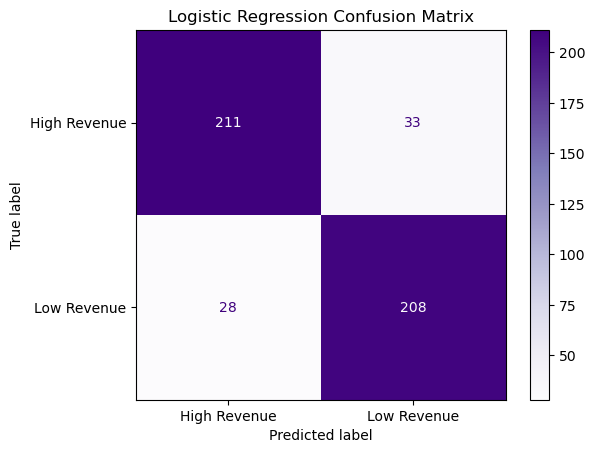

In [262]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_log = confusion_matrix(y_val, y_pred_log)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_log,
    display_labels=['High Revenue', 'Low Revenue']
)

disp.plot(cmap='Purples')
plt.title('Logistic Regression Confusion Matrix')
plt.show()

In [263]:
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=10
)

tree_model.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,10
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [264]:
y_pred_tree = tree_model.predict(X_val)
y_pred_tree[:10]

array([1, 0, 1, 1, 1, 0, 1, 1, 1, 1])

In [265]:
from sklearn.metrics import accuracy_score

tree_accuracy = accuracy_score(y_val, y_pred_tree)

print(tree_accuracy)
print(tree_accuracy * 100, "%")

0.825
82.5 %


In [266]:
from sklearn.metrics import classification_report

print(classification_report(
    y_val,
    y_pred_tree,
    labels=[0, 1],
    target_names=['High Revenue', 'Low Revenue']
))

              precision    recall  f1-score   support

High Revenue       0.83      0.83      0.83       244
 Low Revenue       0.82      0.82      0.82       236

    accuracy                           0.82       480
   macro avg       0.82      0.82      0.82       480
weighted avg       0.82      0.82      0.82       480



In [267]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

,n_estimators,200
,criterion,'gini'
,max_depth,15
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [268]:
y_pred_rf = rf_model.predict(X_val)
y_pred_rf[:10]

array([1, 0, 1, 1, 1, 0, 1, 1, 1, 1])

In [269]:
from sklearn.metrics import accuracy_score

rf_accuracy = accuracy_score(y_val, y_pred_rf)

print(rf_accuracy)
print(rf_accuracy * 100, "%")

0.875
87.5 %


In [270]:
from sklearn.metrics import classification_report

print(classification_report(
    y_val,
    y_pred_rf,
    labels=[0, 1],
    target_names=['High Revenue', 'Low Revenue']
))

              precision    recall  f1-score   support

High Revenue       0.87      0.89      0.88       244
 Low Revenue       0.88      0.86      0.87       236

    accuracy                           0.88       480
   macro avg       0.88      0.87      0.87       480
weighted avg       0.88      0.88      0.87       480



In [271]:
model_comparison = pd.DataFrame({'Model': ['Logistic Regression','Decision Tree','Random Forest'],'Accuracy': [log_accuracy,
        tree_accuracy,
        rf_accuracy]})

model_comparison['Accuracy (%)'] = (model_comparison['Accuracy'] * 100)

model_comparison = model_comparison.sort_values(by='Accuracy',ascending=False)

model_comparison

,Model,Accuracy,Accuracy (%)
2,Random Forest,0.875000,87.500000
0,Logistic Regression,0.872917,87.291667
1,Decision Tree,0.825000,82.500000


## Creating, Validating and Saving the Final Submission File
selecting and training the Random Forest model, the model's predictions were prepared for final submission. The original testing dataset was reloaded to retrieve the movie titles because the title column had been excluded from the model's input features during preprocessing and modelling. The original testing dataset contained 600 movie records and 21 columns.
A new DataFrame named submission was then created using the original movie titles and the predicted revenue categories stored in test_categories. The purpose of this step was to combine each movie title with its corresponding predicted revenue category, either High or Low, in the required submission format.
The first ten records of the submission DataFrame were displayed to inspect the results and confirm that the movie titles matched their predicted categories. The shape of the DataFrame was also checked to confirm that it contained 600 rows and exactly two columns: title and revenue_category.
Missing values were checked using the isnull().sum() function to ensure that every movie had a title and an assigned revenue category. The results showed zero missing values in both columns, confirming that the submission data was complete.
Finally, the completed DataFrame was exported as a CSV file named submission.csv using the to_csv() function. The parameter index=False was included to prevent pandas from adding an unnecessary index column to the file. This ensured that the exported file maintained the required two-column structure and was ready for final inspection and submission.


In [272]:
[name for name in globals() if 'sub' in name.lower()]

['sample_submission']

In [273]:
print(sample_submission.head())
print(sample_submission.shape)
print(sample_submission.columns.tolist())

      title revenue_category
0  Delhi-6               Low
(1, 2)
['title', 'revenue_category']


In [274]:
print(test.head())
print(test.shape)
print(test.columns.tolist())

   writer_count  title_adaption  runtime  users_votes  comments  likes  \
0           3.0               1      141         6337       7.0   43.0   
1           1.0               0       93         8370      57.0  425.0   
2           2.0               1      117        82062      14.0  276.0   
3           9.0               1       81       133925      81.0  301.0   
4           5.0               1      116       190396      74.0  480.0   

   overall_views  dislikes  ratings_imdb  ratings_tomatoes  ...  \
0       165008.0      13.0           6.0                40  ...   
1       281652.0      30.0           7.2                38  ...   
2       187788.0      17.0           7.0                25  ...   
3       200324.0      43.0           5.8                67  ...   
4       740345.0      23.0           6.4                42  ...   

   language_Urdu  language_Vietnamese  language_Welsh  language_Wolof  \
0              0                    0               0               0   
1     

In [275]:
print([name for name in globals() if 'test' in name.lower()])

['test', 'test_countries', 'test_encoded', 'test_country_df', 'test_genres', 'test_genres_df', 'test_censor_df', 'test_languages', 'test_languages_df', 'train_test_split', 'test_scaled']


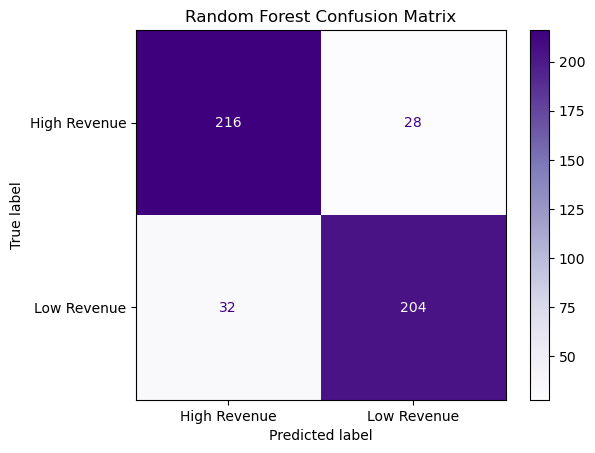

[[216  28]
 [ 32 204]]


In [276]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_val, y_pred_rf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['High Revenue', 'Low Revenue']
)

disp.plot(cmap='Purples')
plt.title('Random Forest Confusion Matrix')
plt.show()

print(cm)

In [277]:
test_predictions = rf_model.predict(test)
print(test_predictions[:10])
print("total prediction:", len(test_predictions))

[1 1 0 0 0 1 1 0 0 0]
total prediction: 600


In [279]:
test_categories = pd.Series(test_predictions).map({0: 'High', 1: 'Low'})
print(test_categories.value_counts())
print(test_categories.head(10))

Low     307
High    293
Name: count, dtype: int64
0     Low
1     Low
2    High
3    High
4    High
5     Low
6     Low
7    High
8    High
9    High
dtype: object


In [280]:
print(train.columns.tolist())
print(test.columns.tolist())

['title', 'country', 'genres', 'language', 'writer_count', 'title_adaption', 'censor_rating', 'release_date', 'runtime', 'dvd_release_date', 'users_votes', 'comments', 'likes', 'overall_views', 'dislikes', 'ratings_imdb', 'ratings_tomatoes', 'ratings_metacritic', 'special_award', 'awards_win', 'awards_nomination', 'revenue_category']
['writer_count', 'title_adaption', 'runtime', 'users_votes', 'comments', 'likes', 'overall_views', 'dislikes', 'ratings_imdb', 'ratings_tomatoes', 'ratings_metacritic', 'special_award', 'awards_win', 'awards_nomination', 'country_Afghanistan', 'country_Albania', 'country_Algeria', 'country_Argentina', 'country_Australia', 'country_Austria', 'country_Belarus', 'country_Belgium', 'country_Bolivia', 'country_Bosnia and Herzegovina', 'country_Brazil', 'country_Bulgaria', 'country_Cambodia', 'country_Cameroon', 'country_Canada', 'country_Cayman Islands', 'country_Chad', 'country_Chile', 'country_China', 'country_Colombia', 'country_Croatia', 'country_Czech Repu

In [281]:
import os
print(os.listdir())

['.ipynb_checkpoints', 'clean_test.csv', 'clean_train.csv', 'Predict_movie.ipynb', 'sample_submission.csv', 'submission.csv', 'test.csv', 'train.csv']


In [282]:
original_test = pd.read_csv('test.csv')
print(original_test.shape)
print(original_test[['title']].head(10))                

(600, 21)
                               title
0                           Delhi-6 
1                Before I Disappear 
2                      Good Year, A 
3                             Brüno 
4      How to Lose a Guy in 10 Days 
5                          Restless 
6                 Young & Beautiful 
7                        Iron Man 3 
8                          Invictus 
9  SpongeBob SquarePants Movie, The 


In [283]:
submission = pd.DataFrame({'title': original_test['title'], 'revenue_category': test_categories.values})
print(submission.head(10))
print(submission.shape)
print(submission.isnull().sum())

                               title revenue_category
0                           Delhi-6               Low
1                Before I Disappear               Low
2                      Good Year, A              High
3                             Brüno              High
4      How to Lose a Guy in 10 Days              High
5                          Restless               Low
6                 Young & Beautiful               Low
7                        Iron Man 3              High
8                          Invictus              High
9  SpongeBob SquarePants Movie, The              High
(600, 2)
title               0
revenue_category    0
dtype: int64


In [284]:
submission = pd.DataFrame({'title': original_test['title'], 'revenue_category': test_categories.values})

In [260]:
submission.to_csv('submission.csv', index=False)

In [261]:
import os
import pandas as pd

print("File exists:", os.path.exists('submission.csv'))

final_submission = pd.read_csv('submission.csv')

print(final_submission.head())
print("Final shape:", final_submission.shape)
print("Missing values:")
print(final_submission.isnull().sum())

File exists: True
                           title revenue_catergory
0                       Delhi-6                Low
1            Before I Disappear                Low
2                  Good Year, A               High
3                         Brüno               High
4  How to Lose a Guy in 10 Days               High
Final shape: (600, 2)
Missing values:
title                0
revenue_catergory    0
dtype: int64
